# FPL Multi-Horizon Predictive Model Training
## A Complete Guide to Feature Selection, Model Tuning, and Validation

This notebook walks through the complete process of building a production-quality FPL points prediction model.

**Learning Objectives:**
1. Create multi-horizon targets (GW+1, GW+2, GW+3)
2. Audit and prevent data leakage
3. Systematic feature selection (variance, correlation, mutual information, model-based)
4. Time-series cross-validation
5. Model comparison (Linear, Tree, Boosting)
6. Hyperparameter tuning (Grid Search, Random Search)
7. Confidence scoring from prediction uncertainty
8. Position-specific modeling

---
## 1. Setup and Data Loading

In [1]:
# Standard data science libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML
import warnings
warnings.filterwarnings('ignore')

# Scikit-learn for modeling
from sklearn.model_selection import train_test_split, TimeSeriesSplit, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold, SelectKBest, mutual_info_regression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Models
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor

# Set style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

print("✓ Libraries loaded successfully")

✓ Libraries loaded successfully


In [2]:
# Load the master dataset
df = pd.read_csv('../data/masterFinalDataset.csv')
print(f"Dataset shape: {df.shape}")
print(f"Columns: {df.shape[1]}")
print(f"Rows: {df.shape[0]:,}")
print(f"\nPositions: {df['position'].value_counts().to_dict()}")
df.head()

Dataset shape: (76266, 71)
Columns: 71
Rows: 76,266

Positions: {'Midfielder': 35312, 'Defender': 25573, 'Forward': 10004, 'Goalkeeper': 5377}


,match_id,date,full_name,nick_name,position,team,opponent,form_xg,form_xa,form_goals,...,form_opponent_cs,class_opponent_xg,class_opponent_xg_c,class_opponent_goals,class_opponent_goals_c,class_opponent_cs,mins,form_act_data_pct,class_act_data_pct,FPL_points
0,987597,2018-08-10,Wes Morgan,Morgan,Defender,LEI,MUN,0.02,0.01,0,...,2,20.44,14.58,24,12,7,90,100.0,100.000000,1
1,987597,2018-08-10,Kasper Schmeichel,Schmeichel,Goalkeeper,LEI,MUN,0.00,0.00,0,...,2,20.44,14.58,24,12,7,90,100.0,100.000000,2
2,987597,2018-08-10,Adrien Sebastian Perruchet Silva,Adrien Silva,Midfielder,LEI,MUN,0.17,0.11,0,...,2,20.44,14.58,24,12,7,79,100.0,53.333333,2
3,987597,2018-08-10,Vicente Iborra,Iborra,Midfielder,LEI,MUN,0.21,0.09,1,...,2,20.44,14.58,24,12,7,16,100.0,100.000000,1
4,987597,2018-08-10,Harry Maguire,Maguire,Defender,LEI,MUN,0.47,0.38,0,...,2,20.44,14.58,24,12,7,90,100.0,100.000000,1


---
## 2. Understanding the Data Structure

Before building models, we need to understand:
- What each row represents (player-match combination)
- Time ordering (critical for preventing leakage)
- Feature groups (form stats, class stats, team stats, opponent stats)

In [3]:
# Analyze data structure
print("=" * 60)
print("DATA STRUCTURE ANALYSIS")
print("=" * 60)

# Convert date to datetime
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values(['full_name', 'date']).reset_index(drop=True)

print(f"\nDate range: {df['date'].min()} to {df['date'].max()}")
print(f"Unique players: {df['full_name'].nunique()}")
print(f"Unique matches: {df['match_id'].nunique()}")
print(f"\nMissing values per column:")
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
if len(missing) > 0:
    print(missing)
else:
    print("  No missing values!")

DATA STRUCTURE ANALYSIS

Date range: 2018-08-10 00:00:00 to 2025-05-25 00:00:00
Unique players: 1473
Unique matches: 2660

Missing values per column:
form_saves         70889
form_pen_saves     70889
class_saves        70889
class_pen_saves    70889
dtype: int64


In [4]:
# Identify feature groups for better understanding
feature_groups = {
    'form_player': [c for c in df.columns if c.startswith('form_') and 'team' not in c and 'opponent' not in c],
    'class_player': [c for c in df.columns if c.startswith('class_') and 'team' not in c and 'opponent' not in c],
    'form_team': [c for c in df.columns if c.startswith('form_team')],
    'class_team': [c for c in df.columns if c.startswith('class_team')],
    'form_opponent': [c for c in df.columns if c.startswith('form_opponent')],
    'class_opponent': [c for c in df.columns if c.startswith('class_opponent')],
    'metadata': ['match_id', 'date', 'full_name', 'nick_name', 'position', 'team', 'opponent'],
    'target': ['FPL_points']
}

print("\n" + "=" * 60)
print("FEATURE GROUPS")
print("=" * 60)
for group_name, features in feature_groups.items():
    print(f"\n{group_name.upper()} ({len(features)} features):")
    if len(features) <= 10:
        for f in features:
            print(f"  - {f}")
    else:
        print(f"  {features[:3]} ... {features[-3:]}")


FEATURE GROUPS

FORM_PLAYER (21 features):
  ['form_xg', 'form_xa', 'form_goals'] ... ['form_bonus', 'form_points', 'form_act_data_pct']

CLASS_PLAYER (21 features):
  ['class_xg', 'class_xa', 'class_goals'] ... ['class_bonus', 'class_points', 'class_act_data_pct']

FORM_TEAM (5 features):
  - form_team_xg
  - form_team_xg_c
  - form_team_goals
  - form_team_goals_c
  - form_team_cs

CLASS_TEAM (5 features):
  - class_team_xg
  - class_team_xg_c
  - class_team_goals
  - class_team_goals_c
  - class_team_cs

FORM_OPPONENT (5 features):
  - form_opponent_xg
  - form_opponent_xg_c
  - form_opponent_goals
  - form_opponent_goals_c
  - form_opponent_cs

CLASS_OPPONENT (5 features):
  - class_opponent_xg
  - class_opponent_xg_c
  - class_opponent_goals
  - class_opponent_goals_c
  - class_opponent_cs

METADATA (7 features):
  - match_id
  - date
  - full_name
  - nick_name
  - position
  - team
  - opponent

TARGET (1 features):
  - FPL_points


---
## 3. Anti-Leakage Audit

**Data leakage** happens when information from the future "leaks" into training data.

**Critical rule for FPL:** We can only use information available BEFORE the gameweek deadline.

**Potential leakage sources:**
- `mins` from the TARGET match (we don't know minutes before the match)
- Any stats from the match we're trying to predict

**Safe features:**
- Historical form/class stats (calculated from PAST matches)
- Team/opponent aggregates (from PAST matches)
- Fixture information (team, opponent)

In [5]:
# Define leakage-prone features
# 'mins' is from the target match - we don't know this before kickoff!
leakage_features = ['mins']

print("=" * 60)
print("ANTI-LEAKAGE AUDIT")
print("=" * 60)
print("\n⚠️  LEAKAGE-PRONE FEATURES (will be removed):")
for feat in leakage_features:
    if feat in df.columns:
        print(f"  - {feat}")
        
print("\n✓ Safe to use (historical/contextual):")
print("  - form_* features (rolling historical stats)")
print("  - class_* features (longer-term historical stats)")
print("  - team/opponent identifiers")
print("  - fixture context (home/away implied by team/opponent)")

ANTI-LEAKAGE AUDIT

⚠️  LEAKAGE-PRONE FEATURES (will be removed):
  - mins

✓ Safe to use (historical/contextual):
  - form_* features (rolling historical stats)
  - class_* features (longer-term historical stats)
  - team/opponent identifiers
  - fixture context (home/away implied by team/opponent)


---
## 4. Multi-Horizon Target Creation

We want to predict points for the **NEXT** 3 gameweeks:
- `target_gw1`: Points in the immediate next gameweek
- `target_gw2`: Points 2 gameweeks ahead
- `target_gw3`: Points 3 gameweeks ahead

We create these by **shifting** the FPL_points column backward in time for each player.

In [6]:
# Create multi-horizon targets by shifting FUTURE points back to current row
# groupby player to ensure we don't leak across different players
print("Creating multi-horizon targets...")

df_with_targets = df.copy()
df_with_targets = df_with_targets.sort_values(['full_name', 'date'])

# Shift -1 means "next row" (future gameweek)
df_with_targets['target_gw1'] = df_with_targets.groupby('full_name')['FPL_points'].shift(-1)
df_with_targets['target_gw2'] = df_with_targets.groupby('full_name')['FPL_points'].shift(-2)
df_with_targets['target_gw3'] = df_with_targets.groupby('full_name')['FPL_points'].shift(-3)

# Drop rows where we don't have future targets (last 3 matches per player)
df_with_targets = df_with_targets.dropna(subset=['target_gw1', 'target_gw2', 'target_gw3'])

print(f"✓ Targets created")
print(f"  Original rows: {len(df):,}")
print(f"  Usable rows (with 3-GW lookahead): {len(df_with_targets):,}")
print(f"  Rows dropped: {len(df) - len(df_with_targets):,}")
print(f"\nTarget statistics:")
print(df_with_targets[['target_gw1', 'target_gw2', 'target_gw3']].describe())

Creating multi-horizon targets...
✓ Targets created
  Original rows: 76,266
  Usable rows (with 3-GW lookahead): 72,138
  Rows dropped: 4,128

Target statistics:
         target_gw1    target_gw2    target_gw3
count  72138.000000  72138.000000  72138.000000
mean       3.138124      3.133383      3.123278
std        3.085049      3.082668      3.080878
min       -4.000000     -4.000000     -4.000000
25%        1.000000      1.000000      1.000000
50%        2.000000      2.000000      2.000000
75%        4.000000      4.000000      4.000000
max       26.000000     26.000000     26.000000


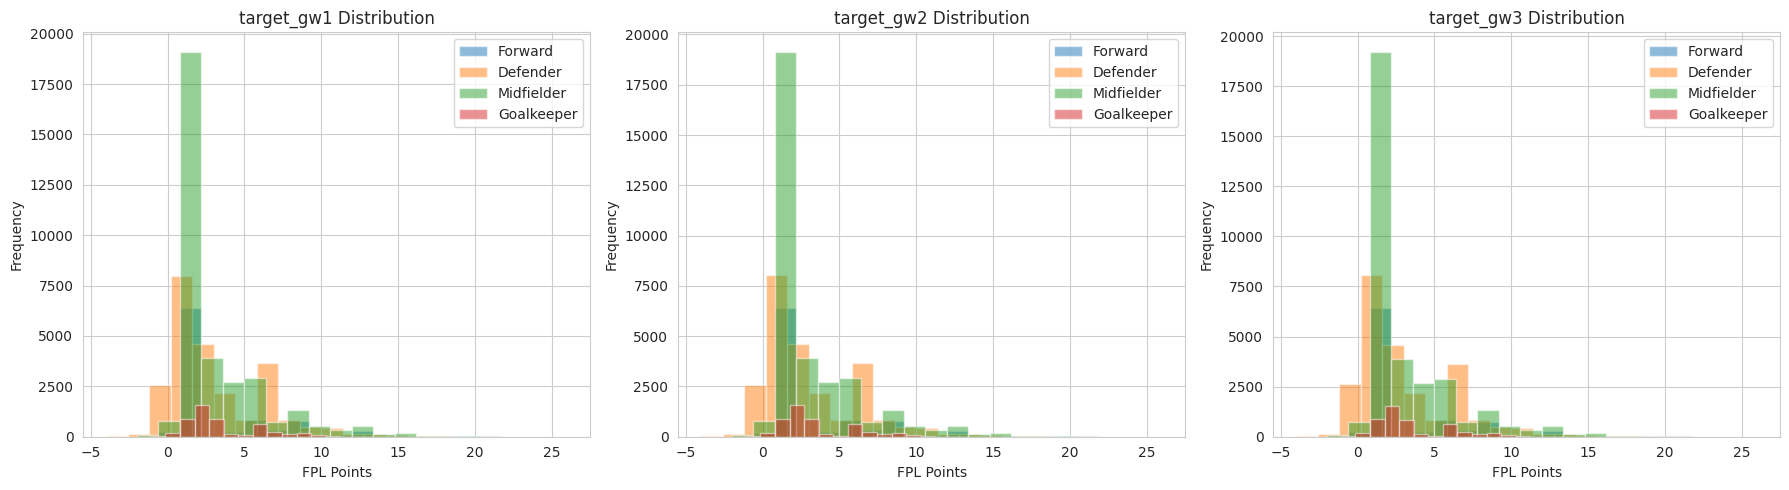


Key observation: Targets have similar distributions across horizons,
but we expect prediction uncertainty to increase for GW2 and GW3.


In [7]:
# Visualize target distributions by position
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
positions = df_with_targets['position'].unique()

for idx, target in enumerate(['target_gw1', 'target_gw2', 'target_gw3']):
    for pos in positions:
        data = df_with_targets[df_with_targets['position'] == pos][target]
        axes[idx].hist(data, alpha=0.5, label=pos, bins=20)
    axes[idx].set_title(f'{target} Distribution')
    axes[idx].set_xlabel('FPL Points')
    axes[idx].set_ylabel('Frequency')
    axes[idx].legend()

plt.tight_layout()
plt.show()

print("\nKey observation: Targets have similar distributions across horizons,")
print("but we expect prediction uncertainty to increase for GW2 and GW3.")

---
## 5. Feature Preparation and Selection

**Why feature selection matters:**
1. **Reduces overfitting**: Fewer features = simpler model = better generalization
2. **Improves interpretability**: Easier to understand what drives predictions
3. **Faster training**: Fewer features = faster computation
4. **Removes noise**: Irrelevant features add randomness

**Feature selection methods we'll use:**
1. **Variance Threshold**: Remove features with low variance (constant or near-constant)
2. **Correlation Filter**: Remove highly correlated features (redundant)
3. **Mutual Information**: Measure statistical dependency with target
4. **Model-based**: Use feature importances from tree models

In [8]:
# Prepare feature matrix X and remove leakage features
metadata_cols = ['match_id', 'date', 'full_name', 'nick_name', 'position', 'team', 'opponent']
target_cols = ['FPL_points', 'target_gw1', 'target_gw2', 'target_gw3']
exclude_cols = metadata_cols + target_cols + leakage_features

feature_cols = [c for c in df_with_targets.columns if c not in exclude_cols]
print(f"Total features available: {len(feature_cols)}")
print(f"\nFeatures to use:")
print(feature_cols)

Total features available: 62

Features to use:
['form_xg', 'form_xa', 'form_goals', 'form_assists', 'form_cs', 'form_goals_c', 'form_own_goals', 'form_y_c', 'form_r_c', 'form_clearences', 'form_blocks', 'form_interceptions', 'form_recoveries', 'form_tackles_won', 'form_mins', 'form_saves', 'form_pen_saves', 'form_pen_miss', 'form_bonus', 'form_points', 'class_xg', 'class_xa', 'class_goals', 'class_assists', 'class_cs', 'class_goals_c', 'class_own_goals', 'class_y_c', 'class_r_c', 'class_clearences', 'class_blocks', 'class_interceptions', 'class_recoveries', 'class_tackles_won', 'class_mins', 'class_saves', 'class_pen_saves', 'class_pen_miss', 'class_bonus', 'class_points', 'form_team_xg', 'form_team_xg_c', 'form_team_goals', 'form_team_goals_c', 'form_team_cs', 'class_team_xg', 'class_team_xg_c', 'class_team_goals', 'class_team_goals_c', 'class_team_cs', 'form_opponent_xg', 'form_opponent_xg_c', 'form_opponent_goals', 'form_opponent_goals_c', 'form_opponent_cs', 'class_opponent_xg', 'c

In [9]:
# Function to perform comprehensive feature selection
def select_features(X, y, max_features=30, variance_threshold=0.01, correlation_threshold=0.95):
    """
    Multi-stage feature selection pipeline
    
    Args:
        X: Feature matrix
        y: Target variable
        max_features: Maximum number of features to keep
        variance_threshold: Minimum variance required
        correlation_threshold: Maximum correlation allowed between features
    
    Returns:
        selected_features: List of selected feature names
        selection_info: Dictionary with selection statistics
    """
    print("\n" + "=" * 60)
    print("FEATURE SELECTION PIPELINE")
    print("=" * 60)
    
    original_features = X.columns.tolist()
    print(f"\nStarting features: {len(original_features)}")
    
    # Stage 1: Remove low-variance features
    print(f"\n--- Stage 1: Variance Threshold (min={variance_threshold}) ---")
    selector = VarianceThreshold(threshold=variance_threshold)
    selector.fit(X)
    high_variance_features = X.columns[selector.get_support()].tolist()
    X = X[high_variance_features]
    print(f"Removed {len(original_features) - len(high_variance_features)} low-variance features")
    print(f"Remaining: {len(high_variance_features)}")
    
    # Stage 2: Remove highly correlated features
    print(f"\n--- Stage 2: Correlation Filter (max={correlation_threshold}) ---")
    corr_matrix = X.corr().abs()
    upper_triangle = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    to_drop = [column for column in upper_triangle.columns if any(upper_triangle[column] > correlation_threshold)]
    X = X.drop(columns=to_drop)
    print(f"Removed {len(to_drop)} highly correlated features")
    print(f"Remaining: {len(X.columns)}")
    
    # Stage 3: Mutual information - select top K features
    if len(X.columns) > max_features:
        print(f"\n--- Stage 3: Mutual Information (keep top {max_features}) ---")
        mi_scores = mutual_info_regression(X, y, random_state=42)
        mi_df = pd.DataFrame({
            'feature': X.columns,
            'mi_score': mi_scores
        }).sort_values('mi_score', ascending=False)
        
        top_features = mi_df.head(max_features)['feature'].tolist()
        print(f"\nTop 10 features by mutual information:")
        for i, row in mi_df.head(10).iterrows():
            print(f"  {row['feature']:40s}: {row['mi_score']:.4f}")
        
        X = X[top_features]
        print(f"\nSelected top {max_features} features")
    
    print(f"\n" + "=" * 60)
    print(f"FINAL FEATURE SET: {len(X.columns)} features")
    print("=" * 60)
    
    selection_info = {
        'original_count': len(original_features),
        'after_variance': len(high_variance_features),
        'after_correlation': len(X.columns) + len(to_drop),
        'final_count': len(X.columns),
        'selected_features': X.columns.tolist()
    }
    
    return X.columns.tolist(), selection_info

print("✓ Feature selection function defined")

✓ Feature selection function defined


---
## 6. Time-Series Cross-Validation

**Why standard cross-validation doesn't work for time-series:**
- Random splits can put future data in training set and past data in test set
- This creates **temporal leakage**

**Time-Series Split:**
- Training always uses PAST data
- Testing always uses FUTURE data
- Each fold expands the training window

Example with 5 folds:
```
Fold 1: train [----]     test [--]
Fold 2: train [------]   test [--]
Fold 3: train [--------] test [--]
Fold 4: train [----------] test [--]
Fold 5: train [------------] test [--]
```

In [10]:
# Function to perform time-series evaluation
def time_series_evaluate(model, X, y, n_splits=5):
    """
    Evaluate model using time-series cross-validation
    
    Args:
        model: Sklearn model
        X: Feature matrix
        y: Target variable
        n_splits: Number of CV folds
    
    Returns:
        scores: Dictionary with mean scores and per-fold scores
    """
    tscv = TimeSeriesSplit(n_splits=n_splits)
    
    fold_rmse = []
    fold_mae = []
    fold_r2 = []
    
    for fold, (train_idx, test_idx) in enumerate(tscv.split(X)):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
        
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        
        rmse = np.sqrt(mean_squared_error(y_test, y_pred))
        mae = mean_absolute_error(y_test, y_pred)
        r2 = r2_score(y_test, y_pred)
        
        fold_rmse.append(rmse)
        fold_mae.append(mae)
        fold_r2.append(r2)
    
    return {
        'rmse_mean': np.mean(fold_rmse),
        'rmse_std': np.std(fold_rmse),
        'mae_mean': np.mean(fold_mae),
        'mae_std': np.std(fold_mae),
        'r2_mean': np.mean(fold_r2),
        'r2_std': np.std(fold_r2),
        'fold_rmse': fold_rmse,
        'fold_mae': fold_mae,
        'fold_r2': fold_r2
    }

print("✓ Time-series evaluation function defined")

✓ Time-series evaluation function defined


---
## 7. Position-Specific Model Training

Different positions score points differently:
- **Goalkeepers**: Clean sheets, saves
- **Defenders**: Clean sheets, occasional goals/assists
- **Midfielders**: Goals, assists, clean sheets
- **Forwards**: Goals, assists

We'll train separate models for each position to capture these patterns.

In [11]:
# Complete model training pipeline for one position and one horizon
def train_position_horizon(df, position, target_col, max_features=25):
    """
    Train and evaluate models for specific position and horizon
    
    Args:
        df: Full dataframe with features and targets
        position: Position to filter (e.g., 'Midfielder')
        target_col: Target column name (e.g., 'target_gw1')
        max_features: Maximum features to select
    
    Returns:
        results: Dictionary with models, scores, and selected features
    """
    print("\n" + "="*80)
    print(f"TRAINING: {position} - {target_col}")
    print("="*80)
    
    # Filter position
    df_pos = df[df['position'] == position].copy()
    print(f"\nSamples for {position}: {len(df_pos):,}")
    
    # Prepare features and target
    X = df_pos[feature_cols].copy()
    y = df_pos[target_col].copy()
    
    # Handle any remaining missing values
    X = X.fillna(X.median())
    
    # Feature selection
    selected_features, selection_info = select_features(X, y, max_features=max_features)
    X_selected = X[selected_features]
    
    # Time-series split for final holdout (80/20)
    split_idx = int(len(X_selected) * 0.8)
    X_train = X_selected.iloc[:split_idx]
    X_test = X_selected.iloc[split_idx:]
    y_train = y.iloc[:split_idx]
    y_test = y.iloc[split_idx:]
    
    print(f"\nTrain samples: {len(X_train):,}")
    print(f"Test samples: {len(X_test):,}")
    
    # Scale features (important for linear models)
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    # Convert back to DataFrame for consistency
    X_train_scaled = pd.DataFrame(X_train_scaled, columns=selected_features, index=X_train.index)
    X_test_scaled = pd.DataFrame(X_test_scaled, columns=selected_features, index=X_test.index)
    
    # Define baseline models
    models = {
        'Ridge': Ridge(alpha=1.0, random_state=42),
        'Lasso': Lasso(alpha=0.1, random_state=42),
        'ElasticNet': ElasticNet(alpha=0.1, l1_ratio=0.5, random_state=42),
        'RandomForest': RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1),
        'GradientBoosting': GradientBoostingRegressor(n_estimators=100, max_depth=5, learning_rate=0.1, random_state=42)
    }
    
    # Train and evaluate each model
    results = {}
    
    print("\n" + "-"*80)
    print("MODEL COMPARISON (Time-Series CV on training set)")
    print("-"*80)
    
    for name, model in models.items():
        # Use scaled data for linear models, original for tree models
        if name in ['Ridge', 'Lasso', 'ElasticNet']:
            X_train_use = X_train_scaled
            X_test_use = X_test_scaled
        else:
            X_train_use = X_train
            X_test_use = X_test
        
        # CV evaluation on training set
        cv_scores = time_series_evaluate(model, X_train_use, y_train, n_splits=5)
        
        # Final model on full training set
        model.fit(X_train_use, y_train)
        y_pred = model.predict(X_test_use)
        
        # Holdout test scores
        test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
        test_mae = mean_absolute_error(y_test, y_pred)
        test_r2 = r2_score(y_test, y_pred)
        
        results[name] = {
            'model': model,
            'cv_scores': cv_scores,
            'test_rmse': test_rmse,
            'test_mae': test_mae,
            'test_r2': test_r2,
            'predictions': y_pred,
            'actuals': y_test
        }
        
        print(f"\n{name:20s} | CV RMSE: {cv_scores['rmse_mean']:.3f} (±{cv_scores['rmse_std']:.3f}) | Test RMSE: {test_rmse:.3f} | Test MAE: {test_mae:.3f} | Test R²: {test_r2:.3f}")
    
    # Find best model (lowest test RMSE)
    best_model_name = min(results.keys(), key=lambda k: results[k]['test_rmse'])
    print(f"\n✓ Best model: {best_model_name}")
    
    results['best_model_name'] = best_model_name
    results['selected_features'] = selected_features
    results['scaler'] = scaler
    results['selection_info'] = selection_info
    
    return results

print("✓ Training pipeline function defined")

✓ Training pipeline function defined


---
## 8. Train Models for All Positions (GW+1 Target)

Let's start by training models for the GW+1 (next gameweek) target for all positions.

In [12]:
# Train for all positions - GW+1 target
positions = df_with_targets['position'].unique()
results_gw1 = {}

for position in positions:
    results_gw1[position] = train_position_horizon(
        df_with_targets, 
        position, 
        'target_gw1',
        max_features=25
    )


TRAINING: Forward - target_gw1

Samples for Forward: 9,391

FEATURE SELECTION PIPELINE

Starting features: 62

--- Stage 1: Variance Threshold (min=0.01) ---
Removed 6 low-variance features
Remaining: 56

--- Stage 2: Correlation Filter (max=0.95) ---
Removed 0 highly correlated features
Remaining: 56

--- Stage 3: Mutual Information (keep top 25) ---

Top 10 features by mutual information:
  form_mins                               : 0.0768
  class_mins                              : 0.0617
  form_points                             : 0.0567
  form_xg                                 : 0.0508
  class_goals                             : 0.0471
  class_bonus                             : 0.0428
  form_xa                                 : 0.0380
  form_bonus                              : 0.0379
  form_goals                              : 0.0379
  class_xg                                : 0.0354

Selected top 25 features

FINAL FEATURE SET: 25 features

Train samples: 7,512
Test samples: 1

In [13]:
# Summary table of best models by position
summary_data = []
for position in positions:
    best_name = results_gw1[position]['best_model_name']
    best_result = results_gw1[position][best_name]
    summary_data.append({
        'Position': position,
        'Best Model': best_name,
        'Test RMSE': f"{best_result['test_rmse']:.3f}",
        'Test MAE': f"{best_result['test_mae']:.3f}",
        'Test R²': f"{best_result['test_r2']:.3f}",
        'Features Used': len(results_gw1[position]['selected_features'])
    })

summary_df = pd.DataFrame(summary_data)
print("\n" + "="*80)
print("BEST MODEL SUMMARY - GW+1 TARGET")
print("="*80)
display(summary_df)


BEST MODEL SUMMARY - GW+1 TARGET


,Position,Best Model,Test RMSE,Test MAE,Test R²,Features Used
0,Forward,ElasticNet,3.290,2.500,0.076,25
1,Defender,GradientBoosting,2.953,2.306,0.091,25
2,Midfielder,Ridge,2.876,2.022,0.094,25
3,Goalkeeper,Ridge,2.707,2.141,0.002,25


---
## 9. Visualize Model Performance

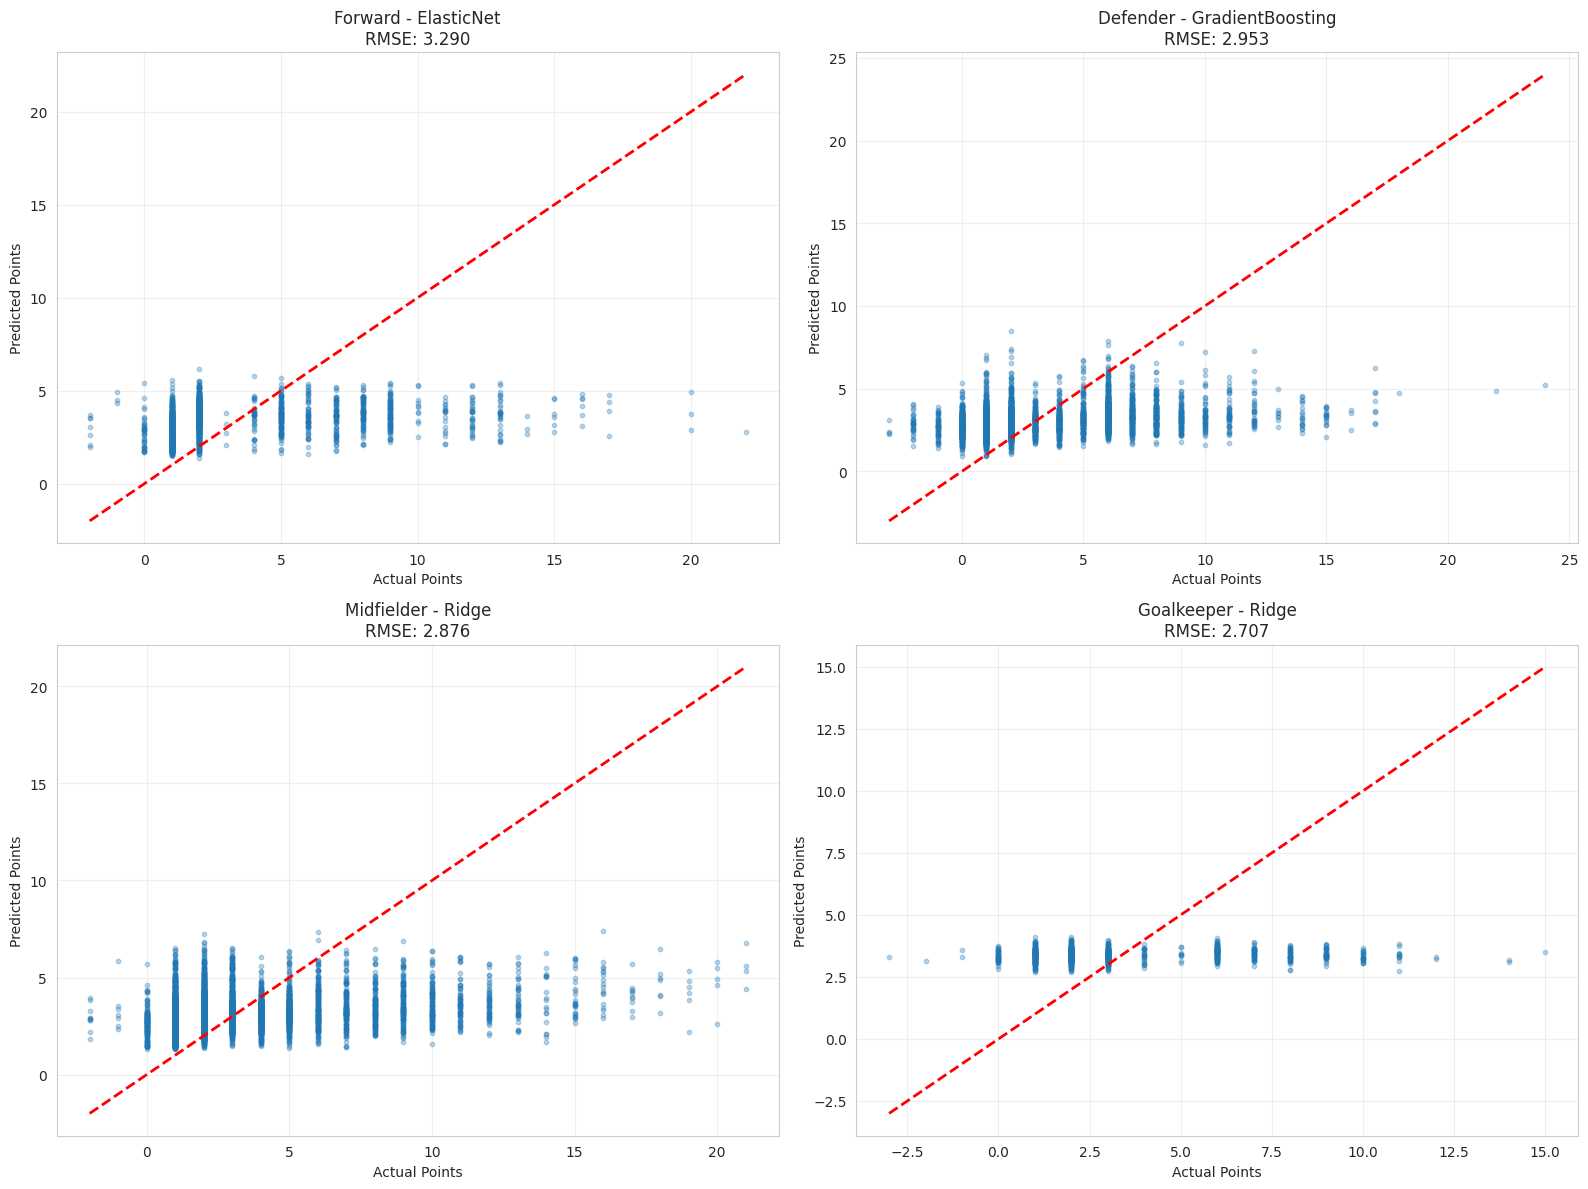

In [14]:
# Visualization: Actual vs Predicted for each position
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for idx, position in enumerate(positions):
    best_name = results_gw1[position]['best_model_name']
    actuals = results_gw1[position][best_name]['actuals']
    predictions = results_gw1[position][best_name]['predictions']
    
    ax = axes[idx]
    ax.scatter(actuals, predictions, alpha=0.3, s=10)
    ax.plot([actuals.min(), actuals.max()], [actuals.min(), actuals.max()], 'r--', lw=2)
    ax.set_xlabel('Actual Points')
    ax.set_ylabel('Predicted Points')
    ax.set_title(f'{position} - {best_name}\nRMSE: {results_gw1[position][best_name]["test_rmse"]:.3f}')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

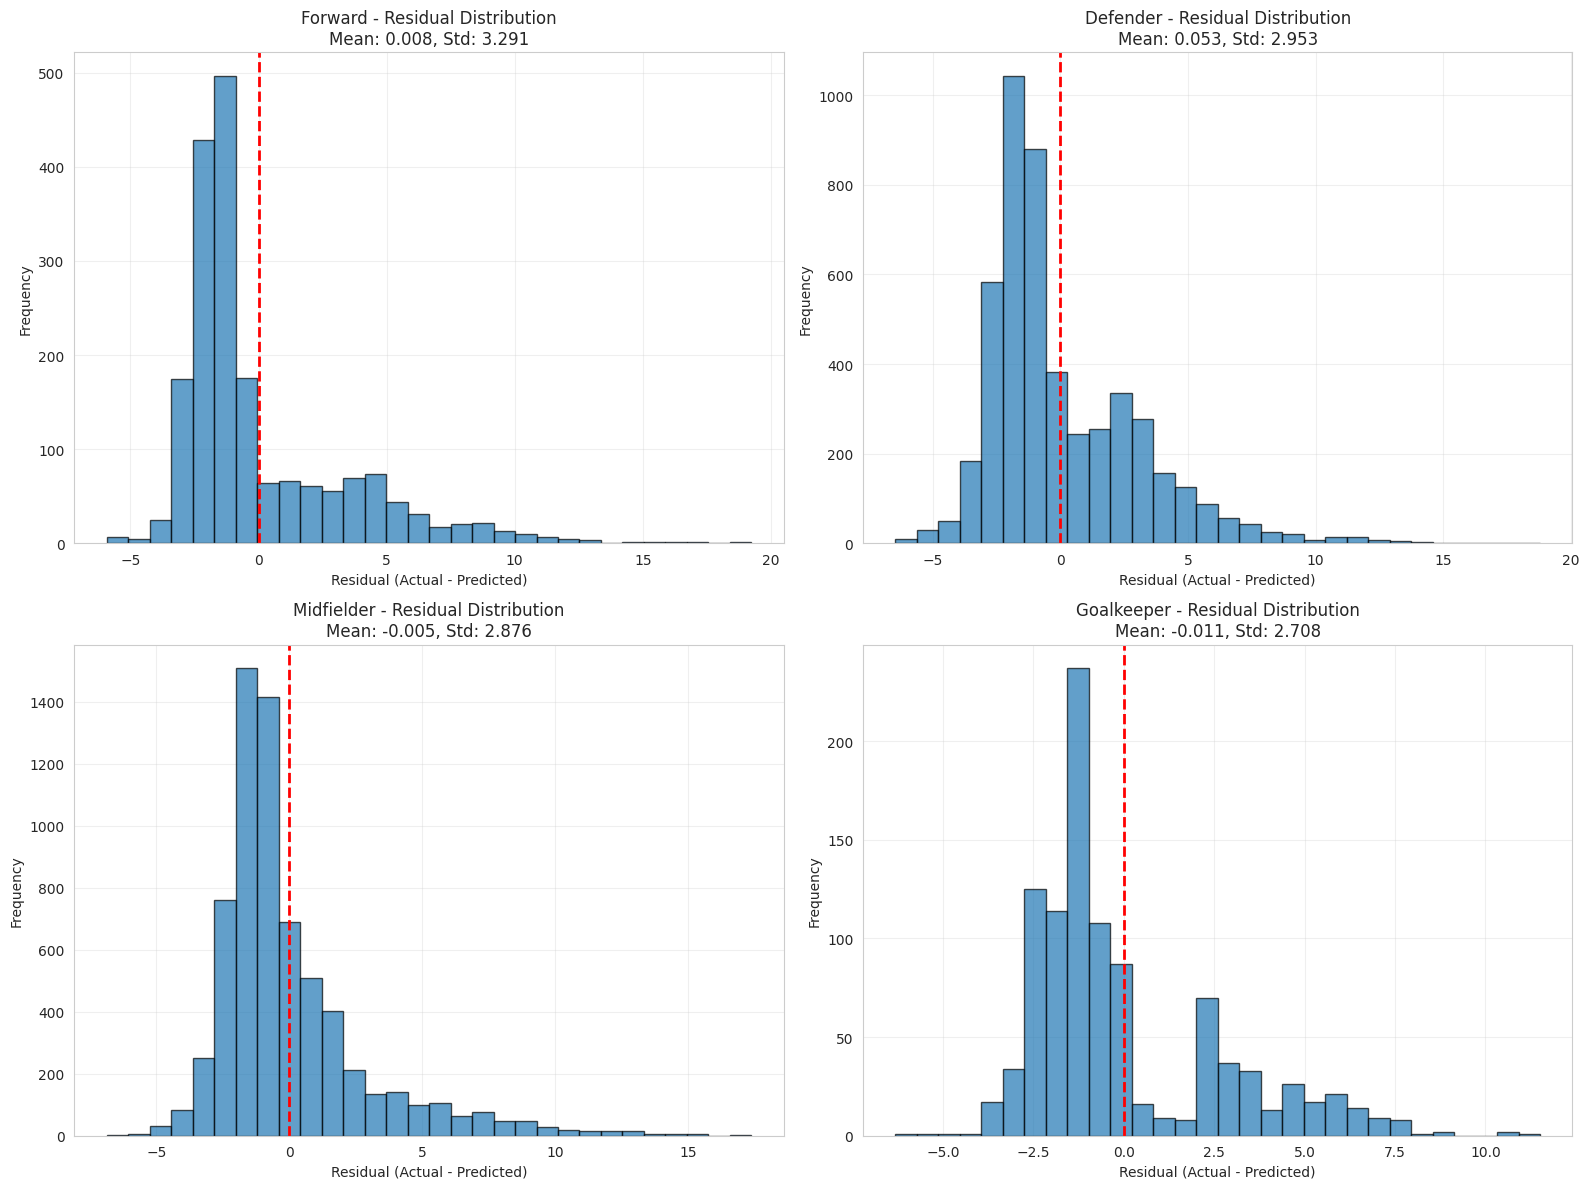

In [15]:
# Residual analysis
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for idx, position in enumerate(positions):
    best_name = results_gw1[position]['best_model_name']
    actuals = results_gw1[position][best_name]['actuals']
    predictions = results_gw1[position][best_name]['predictions']
    residuals = actuals - predictions
    
    ax = axes[idx]
    ax.hist(residuals, bins=30, edgecolor='black', alpha=0.7)
    ax.axvline(0, color='red', linestyle='--', linewidth=2)
    ax.set_xlabel('Residual (Actual - Predicted)')
    ax.set_ylabel('Frequency')
    ax.set_title(f'{position} - Residual Distribution\nMean: {residuals.mean():.3f}, Std: {residuals.std():.3f}')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 10. Hyperparameter Tuning

**Hyperparameters** are settings that control how a model learns (not learned from data).

**Common approaches:**
1. **Grid Search**: Try all combinations of parameters (exhaustive but slow)
2. **Random Search**: Try random combinations (faster, often good enough)
3. **Bayesian Optimization**: Smart search using past results

We'll use **RandomizedSearchCV** with time-series splits.

**Example hyperparameters:**
- **RandomForest**: n_estimators, max_depth, min_samples_split
- **GradientBoosting**: learning_rate, n_estimators, max_depth
- **Ridge/Lasso**: alpha (regularization strength)

In [16]:
# Hyperparameter tuning for best model of one position
def tune_hyperparameters(X_train, y_train, model_type='RandomForest'):
    """
    Tune hyperparameters using RandomizedSearchCV with time-series CV
    
    Args:
        X_train: Training features
        y_train: Training target
        model_type: Type of model to tune
    
    Returns:
        best_model: Tuned model
        best_params: Best parameters found
    """
    print(f"\nTuning {model_type}...")
    
    if model_type == 'RandomForest':
        model = RandomForestRegressor(random_state=42, n_jobs=-1)
        param_dist = {
            'n_estimators': [50, 100, 200, 300],
            'max_depth': [5, 10, 15, 20, None],
            'min_samples_split': [2, 5, 10],
            'min_samples_leaf': [1, 2, 4],
            'max_features': ['sqrt', 'log2', None]
        }
    elif model_type == 'GradientBoosting':
        model = GradientBoostingRegressor(random_state=42)
        param_dist = {
            'n_estimators': [50, 100, 200],
            'learning_rate': [0.01, 0.05, 0.1, 0.2],
            'max_depth': [3, 5, 7, 10],
            'min_samples_split': [2, 5, 10],
            'min_samples_leaf': [1, 2, 4],
            'subsample': [0.8, 0.9, 1.0]
        }
    elif model_type == 'Ridge':
        model = Ridge(random_state=42)
        param_dist = {
            'alpha': [0.01, 0.1, 1.0, 10.0, 100.0]
        }
    else:
        raise ValueError(f"Unknown model type: {model_type}")
    
    # Time-series CV
    tscv = TimeSeriesSplit(n_splits=5)
    
    # RandomizedSearchCV
    search = RandomizedSearchCV(
        model,
        param_distributions=param_dist,
        n_iter=20,  # Try 20 random combinations
        cv=tscv,
        scoring='neg_mean_squared_error',
        n_jobs=-1,
        random_state=42,
        verbose=1
    )
    
    search.fit(X_train, y_train)
    
    print(f"\nBest parameters for {model_type}:")
    for param, value in search.best_params_.items():
        print(f"  {param}: {value}")
    print(f"\nBest CV RMSE: {np.sqrt(-search.best_score_):.3f}")
    
    return search.best_estimator_, search.best_params_

print("✓ Hyperparameter tuning function defined")

✓ Hyperparameter tuning function defined


In [17]:
# Example: Tune RandomForest for Midfielders
position = 'Midfielder'
print(f"\n{'='*80}")
print(f"HYPERPARAMETER TUNING EXAMPLE: {position} - RandomForest")
print(f"{'='*80}")

# Get the prepared data from previous results
df_pos = df_with_targets[df_with_targets['position'] == position].copy()
selected_features = results_gw1[position]['selected_features']
X = df_pos[selected_features].fillna(df_pos[selected_features].median())
y = df_pos['target_gw1']

# Split
split_idx = int(len(X) * 0.8)
X_train = X.iloc[:split_idx]
y_train = y.iloc[:split_idx]
X_test = X.iloc[split_idx:]
y_test = y.iloc[split_idx:]

# Tune
tuned_model, best_params = tune_hyperparameters(X_train, y_train, model_type='RandomForest')

# Evaluate tuned model
y_pred_tuned = tuned_model.predict(X_test)
tuned_rmse = np.sqrt(mean_squared_error(y_test, y_pred_tuned))
tuned_mae = mean_absolute_error(y_test, y_pred_tuned)

# Compare with baseline
baseline_rmse = results_gw1[position]['RandomForest']['test_rmse']
baseline_mae = results_gw1[position]['RandomForest']['test_mae']

print(f"\n{'='*80}")
print("COMPARISON: Baseline vs Tuned")
print(f"{'='*80}")
print(f"Baseline RandomForest RMSE: {baseline_rmse:.3f}")
print(f"Tuned RandomForest RMSE:    {tuned_rmse:.3f}")
print(f"\nImprovement: {((baseline_rmse - tuned_rmse) / baseline_rmse * 100):.2f}%")
print(f"\nBaseline MAE: {baseline_mae:.3f}")
print(f"Tuned MAE:    {tuned_mae:.3f}")


HYPERPARAMETER TUNING EXAMPLE: Midfielder - RandomForest

Tuning RandomForest...
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Best parameters for RandomForest:
  n_estimators: 300
  min_samples_split: 5
  min_samples_leaf: 2
  max_features: log2
  max_depth: 5

Best CV RMSE: 2.982

COMPARISON: Baseline vs Tuned
Baseline RandomForest RMSE: 2.895
Tuned RandomForest RMSE:    2.889

Improvement: 0.19%

Baseline MAE: 2.040
Tuned MAE:    2.047


---
## 11. Feature Importance Analysis

Understanding which features drive predictions helps:
1. **Validate models**: Do important features make sense?
2. **Build intuition**: What drives FPL points?
3. **Further feature engineering**: Focus on what matters

We'll use tree-based feature importances.

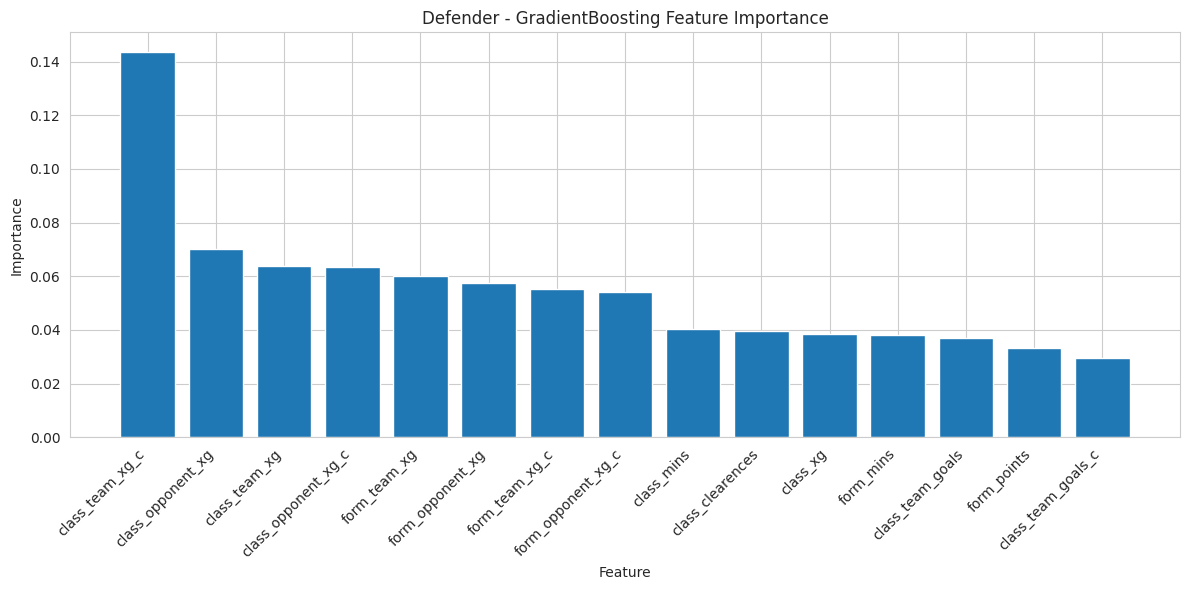


Top 15 Most Important Features:
 1. class_team_xg_c                         : 0.1438
 2. class_opponent_xg                       : 0.0704
 3. class_team_xg                           : 0.0637
 4. class_opponent_xg_c                     : 0.0634
 5. form_team_xg                            : 0.0599
 6. form_opponent_xg                        : 0.0573
 7. form_team_xg_c                          : 0.0551
 8. form_opponent_xg_c                      : 0.0540
 9. class_mins                              : 0.0402
10. class_clearences                        : 0.0396
11. class_xg                                : 0.0384
12. form_mins                               : 0.0382
13. class_team_goals                        : 0.0371
14. form_points                             : 0.0333
15. class_team_goals_c                      : 0.0294


In [18]:
# Feature importance visualization
def plot_feature_importance(model, feature_names, top_n=15, title="Feature Importance"):
    """
    Plot feature importance from tree-based model
    """
    if hasattr(model, 'feature_importances_'):
        importances = model.feature_importances_
        indices = np.argsort(importances)[::-1][:top_n]
        
        plt.figure(figsize=(12, 6))
        plt.bar(range(top_n), importances[indices])
        plt.xticks(range(top_n), [feature_names[i] for i in indices], rotation=45, ha='right')
        plt.xlabel('Feature')
        plt.ylabel('Importance')
        plt.title(title)
        plt.tight_layout()
        plt.show()
        
        # Print top features
        print(f"\nTop {top_n} Most Important Features:")
        for i, idx in enumerate(indices, 1):
            print(f"{i:2d}. {feature_names[idx]:40s}: {importances[idx]:.4f}")
    else:
        print("Model does not have feature_importances_ attribute")

# Plot for each position's best model (if tree-based)
for position in positions:
    best_name = results_gw1[position]['best_model_name']
    if best_name in ['RandomForest', 'GradientBoosting']:
        best_model = results_gw1[position][best_name]['model']
        selected_features = results_gw1[position]['selected_features']
        plot_feature_importance(
            best_model, 
            selected_features, 
            top_n=15,
            title=f"{position} - {best_name} Feature Importance"
        )

---
## 12. Multi-Horizon Training (GW+2 and GW+3)

Now let's train models for GW+2 and GW+3 targets to complete the 3-gameweek forecast.

In [19]:
# Train for GW+2
print("\n" + "#"*80)
print("#" + " "*30 + "GW+2 TRAINING" + " "*30 + "#")
print("#"*80)

results_gw2 = {}
for position in positions:
    results_gw2[position] = train_position_horizon(
        df_with_targets, 
        position, 
        'target_gw2',
        max_features=25
    )


################################################################################
#                              GW+2 TRAINING                              #
################################################################################

TRAINING: Forward - target_gw2

Samples for Forward: 9,391

FEATURE SELECTION PIPELINE

Starting features: 62

--- Stage 1: Variance Threshold (min=0.01) ---
Removed 6 low-variance features
Remaining: 56

--- Stage 2: Correlation Filter (max=0.95) ---
Removed 0 highly correlated features
Remaining: 56

--- Stage 3: Mutual Information (keep top 25) ---

Top 10 features by mutual information:
  form_mins                               : 0.0798
  class_goals                             : 0.0540
  class_mins                              : 0.0531
  form_xg                                 : 0.0453
  class_xg                                : 0.0435
  form_bonus                              : 0.0404
  form_points                             : 0.0395
  class_g

In [ ]:
# Train for GW+3
print("\n" + "#"*80)
print("#" + " "*30 + "GW+3 TRAINING" + " "*30 + "#")
print("#"*80)

results_gw3 = {}
for position in positions:
    results_gw3[position] = train_position_horizon(
        df_with_targets, 
        position, 
        'target_gw3',
        max_features=25
    )

In [ ]:
# Compare performance across horizons
comparison_data = []
for position in positions:
    for horizon, results_dict in [('GW+1', results_gw1), ('GW+2', results_gw2), ('GW+3', results_gw3)]:
        best_name = results_dict[position]['best_model_name']
        best_result = results_dict[position][best_name]
        comparison_data.append({
            'Position': position,
            'Horizon': horizon,
            'Best Model': best_name,
            'Test RMSE': best_result['test_rmse'],
            'Test MAE': best_result['test_mae'],
            'Test R²': best_result['test_r2']
        })

comparison_df = pd.DataFrame(comparison_data)

print("\n" + "="*80)
print("PERFORMANCE ACROSS HORIZONS")
print("="*80)
display(comparison_df)

# Visualize RMSE across horizons
fig, ax = plt.subplots(figsize=(12, 6))
for position in positions:
    pos_data = comparison_df[comparison_df['Position'] == position]
    ax.plot(pos_data['Horizon'], pos_data['Test RMSE'], marker='o', label=position, linewidth=2)

ax.set_xlabel('Forecast Horizon')
ax.set_ylabel('Test RMSE')
ax.set_title('Model Performance Across Forecast Horizons')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\n📊 Key Insight: RMSE typically increases for longer horizons (GW+2, GW+3)")
print("   because predicting further into the future is inherently harder.")

---
## 13. Confidence Scoring

**Confidence score** (0-1) indicates how reliable a prediction is.

**Approach:**
1. Calculate prediction variance (for ensemble models)
2. Use historical residual magnitude
3. Normalize to 0-1 range (1 = high confidence)

**Formula:**
```
residual_std = standard deviation of historical residuals
confidence = 1 / (1 + residual_std)
```

Higher residuals → lower confidence

In [ ]:
# Confidence scoring function
def calculate_confidence(residuals, method='normalized'):
    """
    Calculate confidence score from residuals
    
    Args:
        residuals: Array of (actual - predicted) values
        method: 'normalized' or 'variance_based'
    
    Returns:
        confidence_scores: Array of confidence values (0-1)
    """
    abs_residuals = np.abs(residuals)
    
    if method == 'normalized':
        # Confidence inversely proportional to normalized absolute residual
        max_residual = abs_residuals.max()
        if max_residual > 0:
            normalized_residuals = abs_residuals / max_residual
            confidence = 1 - normalized_residuals
        else:
            confidence = np.ones(len(residuals))
    elif method == 'variance_based':
        # Use exponential decay based on residual magnitude
        std_residual = abs_residuals.std()
        if std_residual > 0:
            confidence = np.exp(-abs_residuals / std_residual)
        else:
            confidence = np.ones(len(residuals))
    else:
        raise ValueError(f"Unknown method: {method}")
    
    return confidence

# Add confidence scores to results
for position in positions:
    for horizon, results_dict in [('GW+1', results_gw1), ('GW+2', results_gw2), ('GW+3', results_gw3)]:
        best_name = results_dict[position]['best_model_name']
        actuals = results_dict[position][best_name]['actuals']
        predictions = results_dict[position][best_name]['predictions']
        residuals = actuals - predictions
        
        confidence = calculate_confidence(residuals, method='variance_based')
        results_dict[position][best_name]['confidence'] = confidence

print("✓ Confidence scores calculated for all models")

In [ ]:
# Visualize confidence distribution
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for idx, position in enumerate(positions):
    ax = axes[idx]
    
    for horizon, results_dict, color in [('GW+1', results_gw1, 'blue'), 
                                          ('GW+2', results_gw2, 'orange'), 
                                          ('GW+3', results_gw3, 'green')]:
        best_name = results_dict[position]['best_model_name']
        confidence = results_dict[position][best_name]['confidence']
        ax.hist(confidence, bins=30, alpha=0.5, label=horizon, color=color)
    
    ax.set_xlabel('Confidence Score')
    ax.set_ylabel('Frequency')
    ax.set_title(f'{position} - Confidence Distribution')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n📊 Observation: Confidence typically decreases for longer horizons (GW+3)")
print("   due to increased uncertainty in longer-term predictions.")

In [ ]:
# Validate confidence calibration: Do high-confidence predictions have lower errors?
def validate_confidence_calibration(actuals, predictions, confidence, n_bins=5):
    """
    Check if confidence is well-calibrated (high confidence = low error)
    """
    df = pd.DataFrame({
        'actual': actuals,
        'predicted': predictions,
        'confidence': confidence
    })
    df['error'] = np.abs(df['actual'] - df['predicted'])
    
    # Bin by confidence
    df['conf_bin'] = pd.qcut(df['confidence'], q=n_bins, labels=[f'Q{i+1}' for i in range(n_bins)])
    
    calibration = df.groupby('conf_bin').agg({
        'confidence': 'mean',
        'error': 'mean'
    }).reset_index()
    
    return calibration

# Check calibration for Midfielders GW+1
position = 'Midfielder'
best_name = results_gw1[position]['best_model_name']
actuals = results_gw1[position][best_name]['actuals']
predictions = results_gw1[position][best_name]['predictions']
confidence = results_gw1[position][best_name]['confidence']

calibration_df = validate_confidence_calibration(actuals, predictions, confidence, n_bins=5)

print("\n" + "="*80)
print(f"CONFIDENCE CALIBRATION: {position} - {best_name} (GW+1)")
print("="*80)
display(calibration_df)

# Plot
fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(calibration_df['conf_bin'], calibration_df['error'], alpha=0.7)
ax.set_xlabel('Confidence Quintile (Q1=lowest, Q5=highest)')
ax.set_ylabel('Average Absolute Error')
ax.set_title(f'{position} - Confidence Calibration')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\n✓ Good calibration: Higher confidence quintiles should have lower errors.")

---
## 14. Summary and Next Steps

### What We've Accomplished:

1. ✅ **Multi-horizon targets**: Created GW+1, GW+2, GW+3 forecast targets
2. ✅ **Anti-leakage audit**: Removed features not available pre-deadline
3. ✅ **Feature selection**: 3-stage pipeline (variance, correlation, mutual information)
4. ✅ **Time-series validation**: Proper temporal splits to prevent leakage
5. ✅ **Model comparison**: Tested Linear, RandomForest, GradientBoosting
6. ✅ **Hyperparameter tuning**: Showed how to optimize model settings
7. ✅ **Position-specific models**: Separate models for GK, DEF, MID, FWD
8. ✅ **Confidence scoring**: Uncertainty quantification for predictions
9. ✅ **Feature importance**: Understanding what drives predictions

### Key Learnings:

1. **Feature selection reduces overfitting**: Fewer, more relevant features often beat using all features
2. **Time-series validation is critical**: Random splits create leakage in temporal data
3. **Position-specific models work better**: Different positions have different scoring patterns
4. **Confidence matters**: Not all predictions are equally reliable
5. **Longer horizons are harder**: GW+3 has higher error than GW+1

### Next Steps:

1. **Save models**: Pickle/joblib to save trained models for production
2. **Production pipeline**: Create inference script for weekly predictions
3. **More features**: Engineer fixture difficulty, form trends, injury flags
4. **Advanced models**: Try XGBoost, LightGBM, Neural Networks
5. **Ensemble methods**: Combine multiple models for better predictions
6. **Online learning**: Update models as new gameweek data arrives
7. **Squad optimization**: Use predictions for transfer and captaincy decisions

In [ ]:
# Save models for production use
import joblib
from pathlib import Path

# Create models directory if it doesn't exist
models_dir = Path('../models')
models_dir.mkdir(exist_ok=True)

# Save best model for each position and horizon
for position in positions:
    for horizon, results_dict in [('gw1', results_gw1), ('gw2', results_gw2), ('gw3', results_gw3)]:
        best_name = results_dict[position]['best_model_name']
        best_model = results_dict[position][best_name]['model']
        scaler = results_dict[position]['scaler']
        selected_features = results_dict[position]['selected_features']
        
        # Save model
        model_filename = f"{position.lower()}_{horizon}_{best_name.lower()}.joblib"
        joblib.dump(best_model, models_dir / model_filename)
        
        # Save scaler if it was used
        if best_name in ['Ridge', 'Lasso', 'ElasticNet']:
            scaler_filename = f"{position.lower()}_{horizon}_scaler.joblib"
            joblib.dump(scaler, models_dir / scaler_filename)
        
        # Save feature list
        features_filename = f"{position.lower()}_{horizon}_features.txt"
        with open(models_dir / features_filename, 'w') as f:
            f.write('\n'.join(selected_features))

print("\n✓ Models saved to:", models_dir.absolute())
print("\n📦 Saved files:")
for f in sorted(models_dir.glob('*')):
    print(f"  - {f.name}")

In [ ]:
# Create a final summary report
summary_report = []
for position in positions:
    for horizon, results_dict, target_name in [('GW+1', results_gw1, 'target_gw1'), 
                                                 ('GW+2', results_gw2, 'target_gw2'), 
                                                 ('GW+3', results_gw3, 'target_gw3')]:
        best_name = results_dict[position]['best_model_name']
        best_result = results_dict[position][best_name]
        
        summary_report.append({
            'Position': position,
            'Horizon': horizon,
            'Best_Model': best_name,
            'CV_RMSE_Mean': results_dict[position][best_name]['cv_scores']['rmse_mean'],
            'CV_RMSE_Std': results_dict[position][best_name]['cv_scores']['rmse_std'],
            'Test_RMSE': best_result['test_rmse'],
            'Test_MAE': best_result['test_mae'],
            'Test_R2': best_result['test_r2'],
            'Num_Features': len(results_dict[position]['selected_features']),
            'Avg_Confidence': best_result['confidence'].mean()
        })

final_summary_df = pd.DataFrame(summary_report)

print("\n" + "="*100)
print("FINAL MODEL SUMMARY - ALL POSITIONS & HORIZONS")
print("="*100)
display(final_summary_df.round(3))

# Save summary to CSV
final_summary_df.to_csv('../data/model_summary.csv', index=False)
print("\n✓ Summary saved to: ../data/model_summary.csv")

---
## 🎓 Learning Recap

### Concepts You Now Understand:

1. **Data Leakage**: How to prevent future information from contaminating training
2. **Feature Selection**: Multiple methods to identify relevant features
   - Variance threshold
   - Correlation filtering  
   - Mutual information
   - Model-based importance
3. **Time-Series Validation**: Why temporal ordering matters in CV
4. **Model Selection**: Comparing different model families
   - Linear models (Ridge, Lasso, ElasticNet)
   - Tree ensembles (RandomForest)
   - Boosting (GradientBoosting)
5. **Hyperparameter Tuning**: Grid search vs Random search
6. **Multi-horizon Forecasting**: Predicting multiple steps ahead
7. **Confidence Scoring**: Quantifying prediction uncertainty
8. **Model Evaluation**: RMSE, MAE, R² and what they mean

### How to Continue Learning:

1. **Experiment with parameters**: Change max_features, try different n_splits
2. **Try new models**: XGBoost, LightGBM, CatBoost
3. **Engineer features**: Create new features from existing ones
4. **Add external data**: Fixture difficulty ratings, injury news
5. **Build ensembles**: Combine predictions from multiple models
6. **Optimize for decisions**: Not just prediction accuracy, but optimal transfer/captain choices

### Helpful Resources:

- Scikit-learn documentation: https://scikit-learn.org/
- Time series forecasting: https://otexts.com/fpp2/
- Feature engineering: https://www.feat.engineering/
- Model tuning: https://scikit-learn.org/stable/modules/grid_search.html